In [1]:
import time

import pandas as pd
import torch

from fxml import config
from fxml.datasets.splits import walk_forward_splits
from fxml.datasets.table import build_table
from fxml.db.connection import connect
from fxml.db.repository import load_bars
from fxml.evaluation import plots
from fxml.training.experiment import Settings, run_fold

plots.apply_style()
print("device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")

bars = load_bars(connect(), "EURUSD", "H1", start=config.TRAIN_START)
settings = Settings()
table = build_table(bars, horizon=settings.horizon)
folds = walk_forward_splits(len(table), train_size=31_000, test_size=3_100, gap=settings.horizon)
print(len(table), "rows,", len(folds), "folds")


device: NVIDIA GeForce RTX 5060 Laptop GPU
73347 rows, 13 folds


In [2]:
pd.DataFrame({
    "train_from": [table.index[f.train_start].date() for f in folds],
    "train_to":   [table.index[f.train_end - 1].date() for f in folds],
    "test_from":  [table.index[f.test_start].date() for f in folds],
    "test_to":    [table.index[f.test_end - 1].date() for f in folds],
}, index=range(1, len(folds) + 1))


,train_from,train_to,test_from,test_to
1,2015-01-05,2019-12-31,2019-12-31,2020-06-30
2,2015-01-05,2020-06-30,2020-06-30,2020-12-29
3,2015-01-05,2020-12-29,2020-12-29,2021-06-29
4,2015-01-05,2021-06-29,2021-06-29,2021-12-28
5,2015-01-05,2021-12-27,2021-12-28,2022-06-27
6,2015-01-05,2022-06-26,2022-06-27,2022-12-23
7,2015-01-05,2022-12-23,2022-12-23,2023-06-22
8,2015-01-05,2023-06-22,2023-06-22,2023-12-20
9,2015-01-05,2023-12-20,2023-12-20,2024-06-20
10,2015-01-05,2024-06-20,2024-06-20,2024-12-19


In [3]:
start = time.time()
result = run_fold(table, folds[0], settings)
print(f"trained in {time.time() - start:.0f}s; best epoch {result.best_epoch}")
pd.Series(result.metrics)


trained in 7s; best epoch 2


test_direction_accuracy           0.516129
baseline_majority_accuracy        0.486774
test_rmse                         0.002273
baseline_zero_rmse                0.002282
test_mae                          0.001502
test_rank_corr                    0.091024
best_epoch                        2.000000
n_train                       27949.000000
n_val                          3000.000000
n_test                         3100.000000
dtype: float64

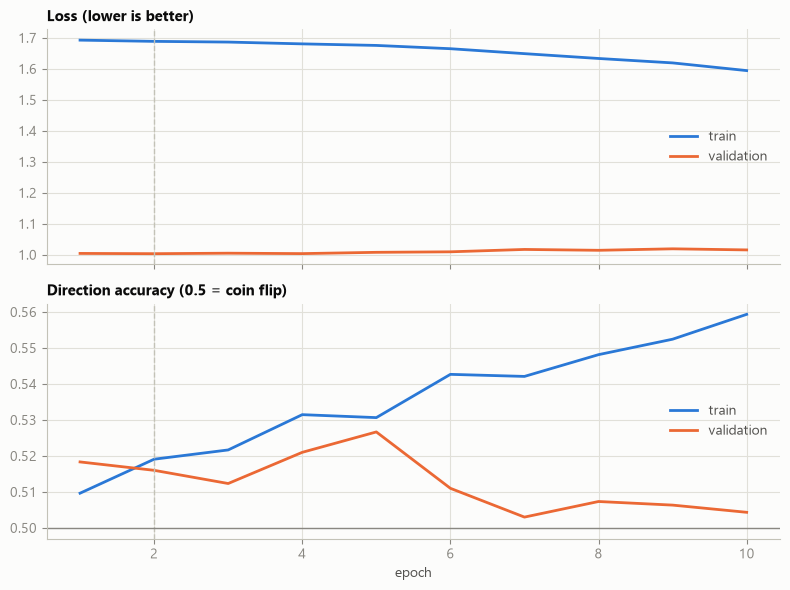

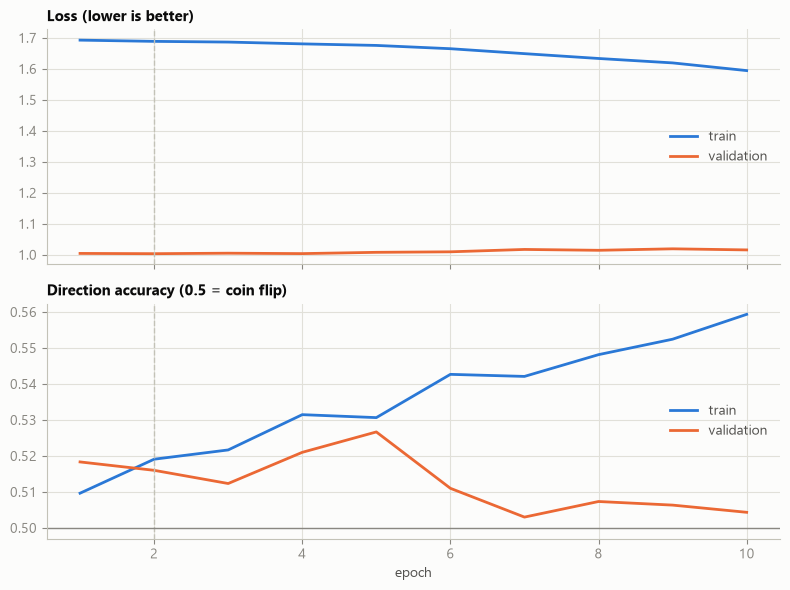

In [4]:
plots.learning_curves(result.history, result.best_epoch)


In [5]:
m = result.metrics
print(f"direction accuracy  model {m['test_direction_accuracy']:.3f}   majority guess {m['baseline_majority_accuracy']:.3f}")
print(f"RMSE                model {m['test_rmse']:.5f}   predict zero  {m['baseline_zero_rmse']:.5f}")
print(f"rank correlation    {m['test_rank_corr']:+.3f}")


direction accuracy  model 0.516   majority guess 0.487
RMSE                model 0.00227   predict zero  0.00228
rank correlation    +0.091


In [6]:
from fxml.training.experiment import run_walk_forward

start = time.time()
wf = run_walk_forward(table, folds, settings)
print(f"done in {(time.time() - start) / 60:.1f} min")
wf.metrics[["test_from", "test_direction_accuracy", "baseline_majority_accuracy",
            "test_rmse", "baseline_zero_rmse", "test_rank_corr", "best_epoch"]]


fold 1/13: accuracy 0.516 (guess 0.487), rank corr +0.091, best epoch 2
fold 2/13: accuracy 0.522 (guess 0.551), rank corr +0.004, best epoch 4
fold 3/13: accuracy 0.504 (guess 0.505), rank corr +0.021, best epoch 4
fold 4/13: accuracy 0.500 (guess 0.486), rank corr -0.019, best epoch 2
fold 5/13: accuracy 0.503 (guess 0.476), rank corr +0.004, best epoch 5
fold 6/13: accuracy 0.516 (guess 0.496), rank corr +0.002, best epoch 1
fold 7/13: accuracy 0.533 (guess 0.477), rank corr +0.034, best epoch 1
fold 8/13: accuracy 0.523 (guess 0.506), rank corr +0.053, best epoch 3
fold 9/13: accuracy 0.513 (guess 0.505), rank corr +0.032, best epoch 3
fold 10/13: accuracy 0.527 (guess 0.505), rank corr +0.045, best epoch 4
fold 11/13: accuracy 0.509 (guess 0.523), rank corr -0.022, best epoch 6
fold 12/13: accuracy 0.514 (guess 0.506), rank corr +0.058, best epoch 2
fold 13/13: accuracy 0.508 (guess 0.481), rank corr +0.028, best epoch 3
done in 2.4 min


,test_from,test_direction_accuracy,baseline_majority_accuracy,test_rmse,baseline_zero_rmse,test_rank_corr,best_epoch
fold,,,,,,,
1,2019-12-31 16:00:00+00:00,0.516129,0.486774,0.002273,0.002282,0.091024,2
2,2020-06-30 22:00:00+00:00,0.521613,0.550968,0.001722,0.001709,0.003975,4
3,2020-12-29 17:00:00+00:00,0.503548,0.504516,0.001474,0.001474,0.020756,4
4,2021-06-29 20:00:00+00:00,0.500323,0.485806,0.001322,0.001317,-0.018523,2
5,2021-12-28 01:00:00+00:00,0.503226,0.476129,0.002265,0.002261,0.003657,5
6,2022-06-27 04:00:00+00:00,0.515806,0.495806,0.003005,0.002997,0.002233,1
7,2022-12-23 09:00:00+00:00,0.532581,0.476774,0.002063,0.002063,0.034327,1
8,2023-06-22 12:00:00+00:00,0.523226,0.505806,0.001831,0.001832,0.053390,3
9,2023-12-20 17:00:00+00:00,0.512581,0.505484,0.001455,0.001454,0.031595,3


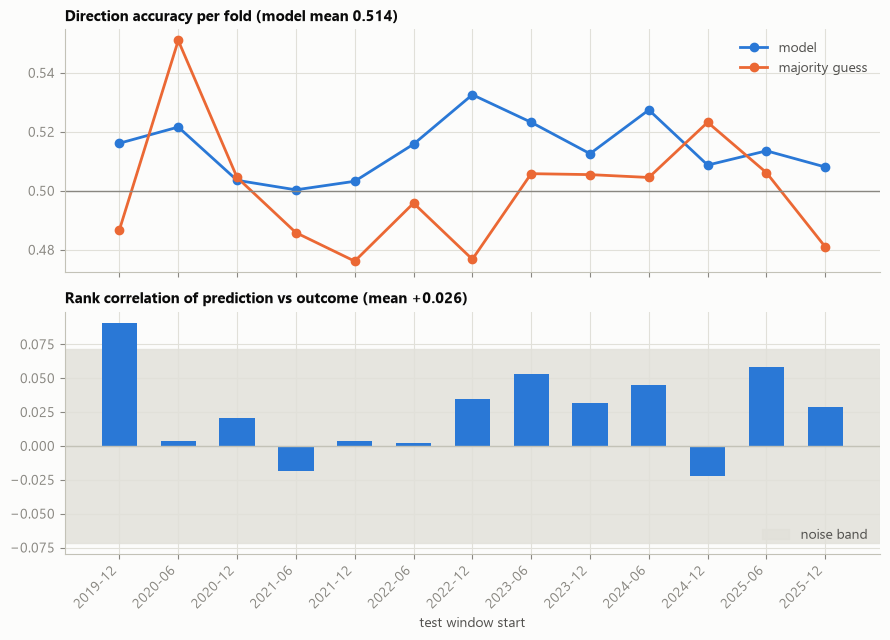

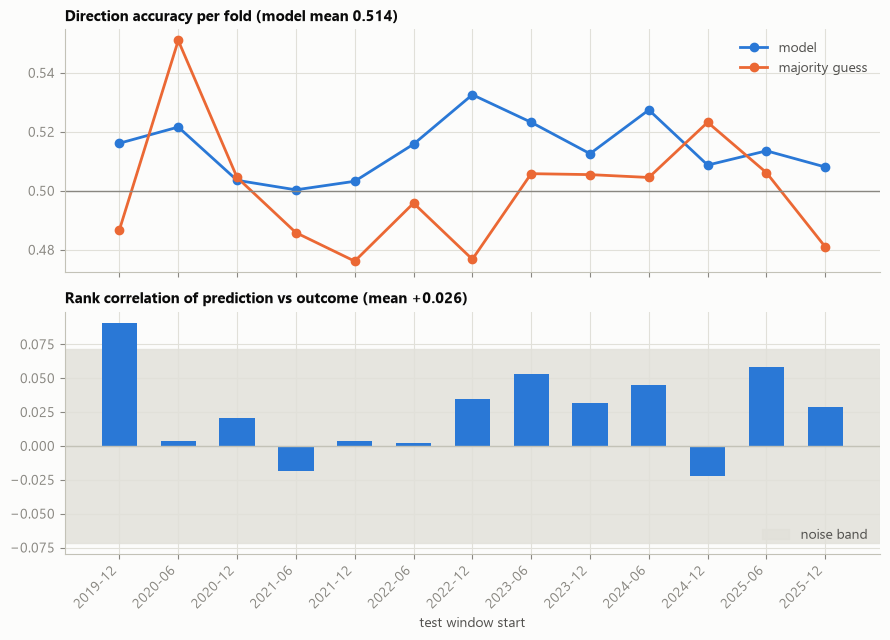

In [7]:
plots.fold_results(wf.metrics)


In [8]:
m = wf.metrics
pred = wf.predictions
print(f"mean accuracy {m['test_direction_accuracy'].mean():.3f} (majority guess {m['baseline_majority_accuracy'].mean():.3f})")
print(f"folds beating the guess: {(m['test_direction_accuracy'] > m['baseline_majority_accuracy']).sum()} of {len(m)}")
print(f"mean rank corr {m['test_rank_corr'].mean():+.3f}; positive in {(m['test_rank_corr'] > 0).sum()} of {len(m)} folds")
pooled = ((pred['prob_up'] > 0.5) == (pred['actual_direction'] > 0.5)).mean()
print(f"pooled accuracy over {len(pred)} out-of-sample bars: {pooled:.3f}")


mean accuracy 0.514 (majority guess 0.500)
folds beating the guess: 10 of 13
mean rank corr +0.026; positive in 11 of 13 folds
pooled accuracy over 40300 out-of-sample bars: 0.514


In [9]:
import numpy as np

pred = wf.predictions.copy()
pred["confidence"] = (pred["prob_up"] - 0.5).abs()
pred["correct"] = (pred["prob_up"] > 0.5) == (pred["actual_direction"] > 0.5)
pred["gross_bps"] = np.sign(pred["prob_up"] - 0.5) * pred["actual_return"] * 1e4
pred["bucket"] = pd.qcut(pred["confidence"], 5,
                         labels=["lowest", "low", "mid", "high", "highest"])

pred.groupby("bucket", observed=True).agg(
    bars=("correct", "size"),
    min_confidence=("confidence", "min"),
    accuracy=("correct", "mean"),
    gross_bps=("gross_bps", "mean"),
)


,bars,min_confidence,accuracy,gross_bps
bucket,,,,
lowest,8060,0.000002,0.492556,-0.136687
low,8060,0.007245,0.505831,0.147034
mid,8060,0.014587,0.513027,0.118388
high,8060,0.022480,0.520099,0.062801
highest,8060,0.033676,0.540323,0.815022


In [10]:
from fxml.evaluation.backtest import backtest, spread_cost, threshold_sweep

cost = spread_cost(bars, config.POINT_SIZE)
sweep = threshold_sweep(wf.predictions, cost, horizon=settings.horizon,
                        thresholds=[0.0, 0.005, 0.01, 0.015, 0.02, 0.025, 0.03, 0.035, 0.04])
sweep[["n_trades", "hit_rate", "gross_bps_per_trade", "net_bps_per_trade",
       "total_return", "max_drawdown"]]


,n_trades,hit_rate,gross_bps_per_trade,net_bps_per_trade,total_return,max_drawdown
threshold,,,,,,
0.000,40300,0.513002,0.201312,-0.499506,-0.503252,-0.564017
0.005,34750,0.517209,0.301137,-0.404546,-0.351449,-0.398319
0.010,29195,0.520843,0.309007,-0.402397,-0.293700,-0.341335
0.015,23718,0.522894,0.304550,-0.412653,-0.244683,-0.289182
0.020,18571,0.526412,0.366968,-0.360794,-0.167508,-0.219660
0.025,13807,0.529876,0.468095,-0.271888,-0.093849,-0.163947
0.030,10151,0.535612,0.680996,-0.070617,-0.017921,-0.111265
0.035,7419,0.543739,0.897486,0.134546,0.024955,-0.063650
0.040,5515,0.545603,0.929465,0.155290,0.021411,-0.062203


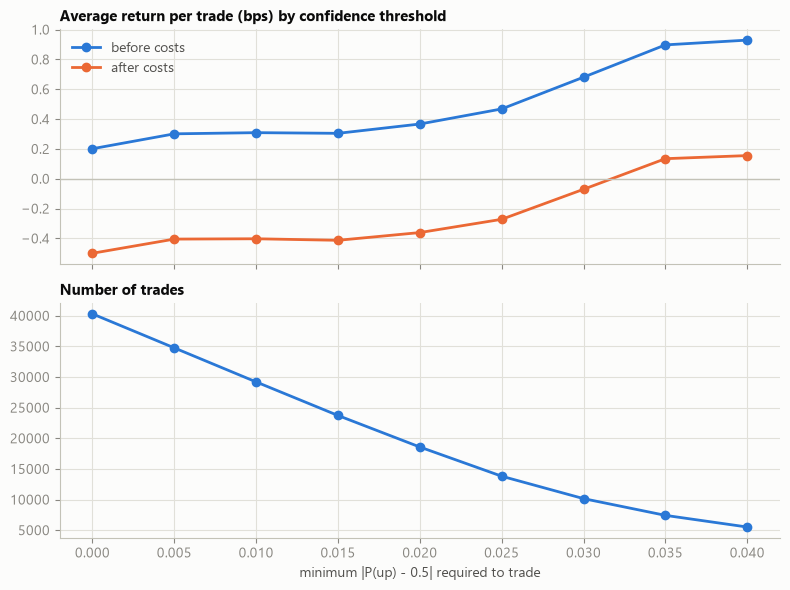

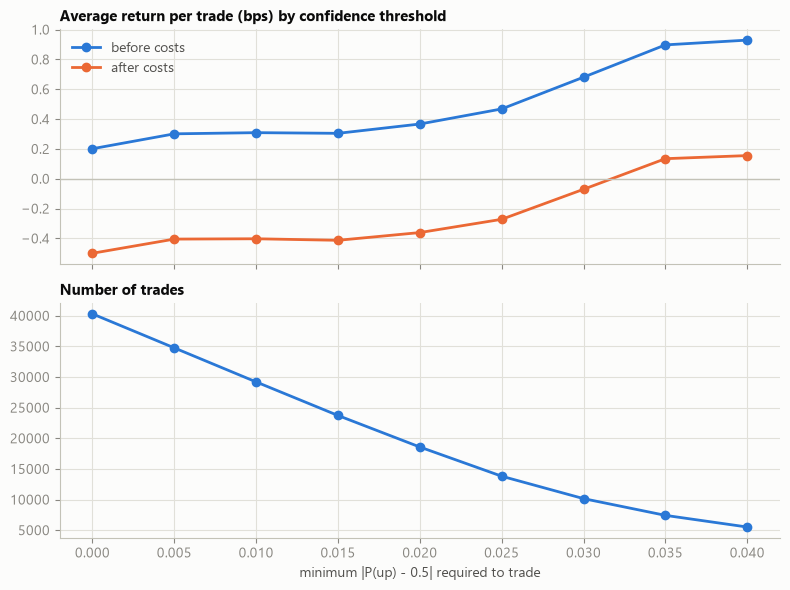

In [11]:
plots.threshold_sweep_chart(sweep)


{'threshold': np.float64(0.03367), 'n_trades': 8060, 'hit_rate': 0.53958, 'gross_bps_per_trade': 0.81502, 'net_bps_per_trade': 0.05683, 'total_return': 0.01145, 'max_drawdown': -0.08936}
extra slippage 0.0 bps -> net +0.06 bps/trade
extra slippage 0.3 bps -> net -0.24 bps/trade
extra slippage 0.6 bps -> net -0.54 bps/trade


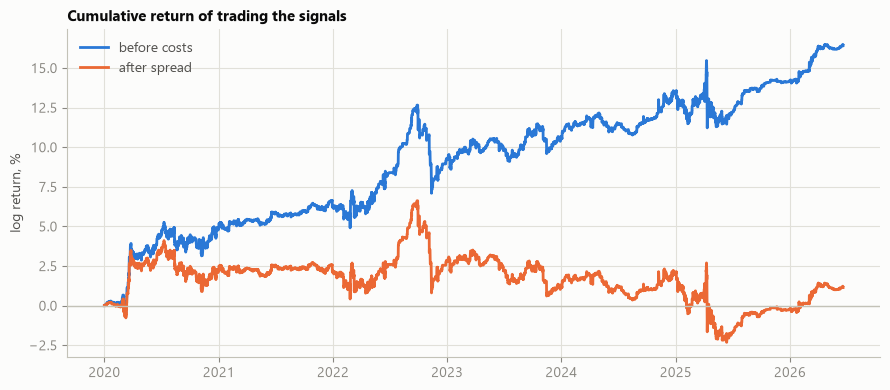

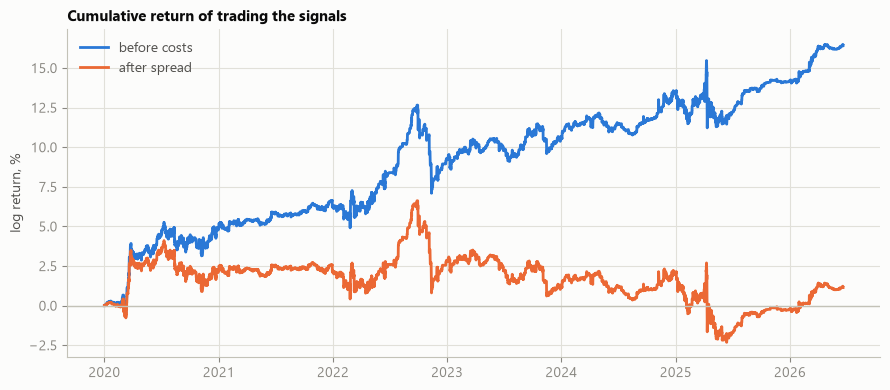

In [12]:
threshold = pred["confidence"].quantile(0.8)
result = backtest(wf.predictions, cost, threshold, settings.horizon)
print({k: round(v, 5) if isinstance(v, float) else v for k, v in result.stats.items()})
for extra in (0.0, 0.3, 0.6):
    s = backtest(wf.predictions, cost, threshold, settings.horizon, extra_cost_bps=extra).stats
    print(f"extra slippage {extra:.1f} bps -> net {s['net_bps_per_trade']:+.2f} bps/trade")
plots.equity_curve(result.gross_equity, result.equity)


In [14]:
import importlib

import fxml.db.repository
import fxml.db.schema

importlib.reload(fxml.db.schema)
importlib.reload(fxml.db.repository)


<module 'fxml.db.repository' from 'D:\\Projects\\Forex machine learning\\src\\fxml\\db\\repository.py'>

In [15]:
from dataclasses import asdict

from fxml.db.repository import load_runs, save_run
from fxml.db.schema import init_db

conn = connect()
init_db(conn)  # adds the two new tables to your existing database
run_id = save_run(conn, name="lstm-h4-baseline", symbol="EURUSD", timeframe="H1",
                  settings=asdict(settings), fold_metrics=wf.metrics, summary=result.stats,
                  notes="top-20% confidence rule, 2015-2026, recorded spread costs")
load_runs(conn)[["name", "created_at", "notes"]]


,name,created_at,notes
run_id,,,
1,lstm-h4-baseline,2026-10-18T23:29:10+00:00,"top-20% confidence rule, 2015-2026, recorded s..."
